# **Assignment 1**


# Preamble

- Loading Packages
- Generating Utilities

In [1]:
%matplotlib inline

from __future__ import annotations
import numpy as np
from dataclasses import dataclass
from typing import Callable, Optional, Tuple, Dict, Any, List
from abc import ABC, abstractmethod
import matplotlib.pyplot as plt

# Model
`Model` is an abstract base class for linear models that hold a weight matrix `W` of shape `(in_dim, out_dim)` and define two required behaviours: batch prediction via `predict_batch(X)` and batch gradient computation, the gradient of the loss with respect to `W`, via `grad_batch(X, Y)`.

In [2]:
class Model:
    """
    Abstract base class for linear models with weight matrix W (d x m).
    """
    def __init__(self,
                 in_dim: int,
                 out_dim: int = 1):
        self.in_dim = int(in_dim)
        self.out_dim = int(out_dim)
        self.W = np.zeros((in_dim, out_dim), dtype=float)

    def predict_batch(self,
                      X: np.ndarray) -> np.ndarray:
        raise NotImplementedError

    def grad_batch(self,
                   X: np.ndarray,
                   Y: np.ndarray) -> np.ndarray:
        raise NotImplementedError


## Linear regression

In this section, you will implement linear regression. The model predicts:
$$
\hat{\mathbf{Y}} = \mathbf{X} \mathbf{W},\qquad \mathbf{X} \in\mathbb{R}^{n \times d},\; \mathbf{W} \in\mathbb{R}^{d \times m},
$$
where $\mathbf{X}$ has each row corresponding to an input vector $\mathbf{x}_i \in \mathbb{R}^{1\times d}$ and targets $\mathbf{Y} \in\mathbb{R}^{n \times m}$ has each row corresponding to a target vector $\mathbf{y}_i \in \mathbb{R}^{1\times m}$.
The per-sample squared-error loss is:
$$
\ell(\mathbf{x}, \mathbf{y}; \mathbf{W}) = \tfrac{1}{2}\,\bigl\|\mathbf{x} \mathbf{W} - \mathbf{y}\bigr\|_2^2,
$$
with the per-sample gradient:
$$
\nabla_\mathbf{W} \ell(\mathbf{x}, \mathbf{y}; \mathbf{W}) \;=\; \mathbf{x}^\top\,(\mathbf{x} \mathbf{W} - \mathbf{y}).
$$
Implement `predict_batch(X)` to compute $\mathbf{X}\mathbf{W}$, and `grad_batch(X, Y)` to compute the outer product above. Assume $\mathbf{x}$ already includes an intercept or bias feature as the first feature. Later code in this notebook will append a one to $\mathbf{x}$ and more generally transform it with either polynomial features or RBF features.

In [3]:
class LinearRegression(Model):
    """
    Batched squared-error linear regression (ordinary least squares).

    Parameters live in `self.W ∈ ℝ^{d×m}` and predictions are `Ŷ = X @ W` for inputs `X ∈ ℝ^{n×d}`.
    This class implements only the forward prediction and the batch gradient (no regularization).

    Args:
        in_dim (int): Number of input features d (assumes user has included a 1 feature in x if a bias unit is desired).
        out_dim (int): Number of outputs/classes m. Defaults to 1.
    """

    def predict_batch(self,
                      X: np.ndarray) -> np.ndarray:
        # Forward pass: matrix multiply features by weights -> predictions (n×m)
        #### BEGIN SOLUTION
        pred = np.matmul(X, self.W)

        #### END SOLUTION
        return pred

    def grad_batch(self,
                   X: np.ndarray,
                   Y: np.ndarray) -> np.ndarray:
        # Ensure targets are 2D (n×m) to match predictions' shape
        Y = Y.reshape(-1, 1) if Y.ndim == 1 else Y

        #### BEGIN SOLUTION
        error = X @ self.W - Y
        mean_err = (X.T @ error) / X.shape[0]
        #### END SOLUTION
        return mean_err


def mse(X, Y, W):
    Yhat = X @ W
    err = Yhat - Y
    return 0.5 * np.mean(np.sum(err**2, axis=1))


In [4]:
print("== Testing LinearRegression (batch) ==")

# 1) predict single-output
d, m = 4, 1
lr = LinearRegression(d, m)
W_true = np.array([[1.0],[-2.0],[0.5],[3.0]])
lr.W = W_true.copy()
X = np.array([[1.0,0.0,2.0,-1.0],[0.0,1.0,0.0,2.0],[3.0,1.0,1.0,0.0]])
assert np.allclose(lr.predict_batch(X), X @ W_true)
# 2) grad_batch closed form on small batch
x_batch = np.array([[1.0,-1.0,2.0,0.0]])
y_batch = np.array([[0.7]])
G = lr.grad_batch(x_batch, y_batch)
err = (x_batch @ lr.W - y_batch)
G_exp = (x_batch.T @ err) / x_batch.shape[0]
assert np.allclose(G, G_exp)
# 3) multi-output grad shape/value
d, m = 3, 2
m2 = LinearRegression(d, m)
m2.W = np.array([[1.0,-1.0],[0.5,0.0],[-2.0,3.0]])
X2 = np.array([[1.0,0.0,2.0],[0.0,1.0,1.0]])
Y2 = X2 @ m2.W
G2 = m2.grad_batch(X2, Y2)
assert np.allclose(G2, 0.0)
# 4) tiny batch descent reduces loss
rng = np.random.default_rng(0)
d, m = 5, 1
m3 = LinearRegression(d, m)
m3.W = rng.normal(scale=0.1, size=(d, m))
X3 = rng.normal(size=(8, d))
W_t = rng.normal(size=(d, m))
Y3 = X3 @ W_t + 0.01 * rng.normal(size=(8, m))
loss0 = mse(X3, Y3, m3.W)
eta = 1e-2
G = m3.grad_batch(X3, Y3)
m3.W -= eta * G
loss1 = mse(X3, Y3, m3.W)
assert loss1 < loss0
print("✅ All LinearRegression tests passed!")


== Testing LinearRegression (batch) ==
✅ All LinearRegression tests passed!


## Ridge regression

In this section, you will implement ridge (L2-regularized) linear regression.
As before, the predictor is
$$
\hat{\mathbf{Y}} = \mathbf{X} \mathbf{W},\qquad \mathbf{X} \in\mathbb{R}^{n \times d},\; \mathbf{W} \in\mathbb{R}^{d \times m},
$$
The difference comes from how we obtain the parameters $\mathbf{W}$, by including a L2 regularizer in addition to the least-squares loss.

Use the per-sample ridge loss:
$$
\ell_{\text{ridge}}(\mathbf{x}, \mathbf{y}; \mathbf{W})
= \tfrac{1}{2}\,\bigl\|\mathbf{x} \mathbf{W} - \mathbf{y}\bigr\|_2^2
+ \tfrac{\lambda}{2}\,\|\mathbf{W}\|_F^2,
$$
and return the per-sample gradient:
$$
\nabla_\mathbf{W} \ell_{\text{ridge}}(\mathbf{x}, \mathbf{y}; \mathbf{W})
\;=\; \mathbf{x}^\top\,(\mathbf{x} \mathbf{W} - \mathbf{y}) \;+\; \lambda \mathbf{W}.
$$

Here, $$\lVert \mathbf{W} \rVert_F = \sqrt{\sum_{i=1}^d \sum_{j=1}^m \lvert w_{ij} \rvert^2}$$
is the Frobenius norm.

NOTE: We generally do not regularize the bias---if you have included a bias term as the first column of $\mathbf{X}$, zero out the corresponding row of $\lambda \mathbf{W}$ before adding it.

In [5]:
class RidgeRegression(LinearRegression):
    """
    L2-regularized linear regression (Ridge).

    Args:
        in_dim (int): Number of input features d (assumes if there is a bias unit, that it is the first feature).
        out_dim (int): Number of outputs/classes m. Defaults to 1.
        lambda_ (float): L2 penalty strength λ.
        penalize_bias (bool): Whether to apply the L2 penalty to the bias column of W.
    """
    def __init__(self,
                 in_dim: int,
                 out_dim: int = 1,
                 lambda_: float = 1.0,
                 penalize_bias: bool = False):
        super().__init__(in_dim, out_dim)
        self.lambda_ = float(lambda_)
        self.penalize_bias = bool(penalize_bias)

    def grad_batch(self,
                   X: np.ndarray,
                   Y: np.ndarray) -> np.ndarray:
        #### BEGIN SOLUTION
        error = X @ self.W - Y
        G = (X.T @ error) / X.shape[0]

        W_reg = self.W.copy()
        if not self.penalize_bias:
            W_reg[0] = 0
        G += self.lambda_ * W_reg
        #### END SOLUTION

        return G


In [6]:
print("== Testing RidgeRegression (batch) ==")

def make_ridge(d, m, lam, penalize_bias):
    try:
        return RidgeRegression(d, m, lambda_=lam, penalize_bias=penalize_bias)
    except TypeError:
        rr = RidgeRegression(d, m, lambda_=lam)
        if hasattr(rr, "penalize_bias"):
            rr.penalize_bias = penalize_bias
        return rr

# 1) predict_batch() correctness
d, m, lam = 5, 1, 0.7
ridge = make_ridge(d, m, lam, penalize_bias=True)
ridge.W = np.array([[1.0],[-2.0],[0.5],[3.0],[-1.5]])
X = np.array([[1.0,0.0,2.0,-1.0,1.0],[0.0,1.0,0.0,2.0,-2.0],[3.0,1.0,1.0,0.0,0.5]])
assert np.allclose(ridge.predict_batch(X), X @ ridge.W)
# 2) grad has lambda*W (no bias exclusion)
x = np.array([[1.0,-1.0,2.0,0.0,0.5]])
y = np.array([[0.7]])
G = ridge.grad_batch(x, y)
err = (x @ ridge.W - y)
G_data = (x.T @ err) / x.shape[0]
assert np.allclose(G, G_data + lam * ridge.W)
# 3) bias exclusion respected
db, lam_b = 6, 1.2
ridge_b = make_ridge(db, 1, lam_b, penalize_bias=False)
ridge_b.W = np.array([[0.2],[-0.3],[0.1],[0.0],[0.7],[-2.0]])
x_b = np.array([[0.4,-1.0,2.0,0.0,1.5,1.0]])
y_b = np.array([[0.25]])
G_b = ridge_b.grad_batch(x_b, y_b)
err_b = (x_b @ ridge_b.W - y_b)
G_data_b = (x_b.T @ err_b) / x_b.shape[0]
G_exp = G_data_b + lam_b * ridge_b.W
G_exp[0,0] -= lam_b * ridge_b.W[0,0]
assert np.allclose(G_b, G_exp)
# 4) shrinkage with zero data
rng = np.random.default_rng(1)
ridge3 = make_ridge(6, 1, 0.8, penalize_bias=True)
ridge3.W = rng.normal(size=(6,1))
W0 = ridge3.W.copy()
G = ridge3.grad_batch(np.zeros((4,6)), np.zeros((4,1)))
ridge3.W -= 1e-2 * G
assert np.linalg.norm(ridge3.W) < np.linalg.norm(W0)
print("✅ All RidgeRegression tests passed!")


== Testing RidgeRegression (batch) ==
✅ All RidgeRegression tests passed!


# Optimizer

`Optimizer` is a class that performs in-place parameter updates on a model at each training step. It exposes a single method `step(model, X, Y)`, which (1) computes the gradient `g = model.grad_batch(X, Y)` implemented by the model, and (2) updates the model’s parameters `model.W` accordingly.

In [7]:
class Optimizer:
    """Abstract batch optimizer API."""
    def step(self,
             model: Model,
             X: np.ndarray,
             Y: np.ndarray):
        raise NotImplementedError


## Mini-batch stochastic gradient descent (SGD).

Mini-batch stochastic gradient descent updates the parameters with a fixed step $\eta$ in the direction of the negative gradient computed using a mini-batch $\mathcal{B}_t$ of $b$ indices, subsampled from indices $\{1, 2, \dots, n\}$, at iteration $t$:
$$
\mathbf{W}_{t+1} = \mathbf{W}_t \;-\; \eta \frac{1}{b} \sum_{i \in \mathcal{B}_t}\,\nabla_\mathbf{W} \ell(\mathbf{x}_i,\mathbf{y}_i; \mathbf{W}_t).
$$

In [8]:
class SGD(Optimizer):
    """
    Mini-batch stochastic gradient descent with a fixed step size eta.

    Args:
        eta (float): Fixed step size of SGD.
    """
    def __init__(self,
                 eta: float = 1e-2):
        self.eta = float(eta)

    def step(self,
             model: Model,
             X: np.ndarray,
             Y: np.ndarray):
        #### BEGIN SOLUTION
        grads = model.grad_batch(X, Y)
        model.W -= self.eta * grads

        #### END SOLUTION


In [9]:
print("== Testing SGD (batch) ==")

# 1) Single step equals W - eta * grad
d, m = 4, 1
eta = 1e-2
sgd = SGD(eta)
model = LinearRegression(d, m)
model.W = np.array([[0.5],[-0.2],[0.1],[1.0]])
Xb = np.array([[1.0,-2.0,0.5,3.0]])
yb = np.array([[0.4]])
G = model.grad_batch(Xb, yb).copy()
W_before = model.W.copy()
sgd.step(model, Xb, yb)
assert np.allclose(model.W, W_before - eta * G)
# 2) few steps reduce loss
rng = np.random.default_rng(0)
d, m = 5, 1
sgd = SGD(eta=5e-3)
model = LinearRegression(d, m)
model.W = rng.normal(scale=0.1, size=(d, m))
X = rng.normal(size=(16, d))
W_true = rng.normal(size=(d, m))
Y = X @ W_true + 0.01 * rng.normal(size=(16, m))
loss0 = mse(X, Y, model.W)
for _ in range(3):
    model.W -= sgd.eta * model.grad_batch(X, Y)
loss1 = mse(X, Y, model.W)
assert loss1 < loss0
# 3) larger eta -> larger step
d, m = 3, 1
Xb = np.array([[1.0,2.0,-1.0]])
yb = np.array([[0.5]])
m1 = LinearRegression(d, m); m1.W[:] = 0.3
m2 = LinearRegression(d, m); m2.W[:] = 0.3
sgd_small = SGD(1e-3); sgd_big = SGD(1e-1)
W1 = m1.W.copy(); sgd_small.step(m1, Xb, yb); d1 = np.linalg.norm(m1.W - W1)
W2 = m2.W.copy(); sgd_big.step(m2, Xb, yb);   d2 = np.linalg.norm(m2.W - W2)
assert d2 > d1
# 4) zero gradient -> no change
model = LinearRegression(4,1)
Xb = np.array([[1.0,0.0,-1.0,2.0]])
model.W = np.array([[0.2],[0.0],[-0.1],[0.3]])
yb = Xb @ model.W
Wb = model.W.copy(); sgd.step(model, Xb, yb)
assert np.allclose(model.W, Wb)
print("✅ All SGD tests passed!")


== Testing SGD (batch) ==
✅ All SGD tests passed!


## Adam optimizer

In the last section, we implemented simple linear regression with SGD updates using a fixed stepsize.
In many cases, it gives benefits to adapt the step size based on the information obtained from seen samples.
In this section, we will extend SGD to a more sophisticated optimizer, the [Adam optimizer](https://arxiv.org/pdf/1412.6980), which uses gradient information from past samples.

In addition to the step size $\eta$, Adam also maintains two states: $\mathbf{M}_t$ and $\mathbf{V}_t$, which respectively store the exponential moving averages of the gradient and squared gradient:
$$
\mathbf{M}_{t} = \beta_1 \mathbf{M}_{t-1} + (1 - \beta_1) c(\mathbf{W_t})
$$

$$
\mathbf{V}_{t} = \beta_2 \mathbf{V}_{t-1} + (1 - \beta_2) (c(\mathbf{W_t}))^2,
$$
where $c(\mathbf{W_t}) = \frac{1}{b} \sum_{i \in \mathcal{B}_t}\,\nabla_\mathbf{W} \ell(\mathbf{x}_i,\mathbf{y}_i; \mathbf{W}_t)$ is the gradient of the loss computed using the mini-batch $\mathcal{B}_t$ and the squared operation is applied element-wise.
Here, $\beta_1, \beta_2 \in [0, 1]$ are hyperparameters to control how much past information influence the moving averages.

Initially, we set $\mathbf{M}_0 = \mathbf{0}, \mathbf{V}_0 = \mathbf{0}$ so we have to perform *initialization bias correction* to ensure the estimates are unbiased:
$$
\hat{\mathbf{M}}_{t} = \frac{\mathbf{M}_t}{1-\beta_1^t}
$$

$$
\hat{\mathbf{V}}_{t} = \frac{\mathbf{V}_t}{1-\beta_2^t}
$$

Finally, we update the model weights
$$
\mathbf{W}_{t} = \mathbf{W}_{t-1} - \eta \frac{\hat{\mathbf{M}}_{t}}{\sqrt{\hat{\mathbf{V}}_{t}} + \mathbf{E}},
$$
where the square root for $v_t$ is element-wise.
Since the update now includes a division based on $\hat{\mathbf{V}}_t$, which can be zero, we add a small term $\mathbf{E}$, where $\mathbf{E}_{ij} = \varepsilon > 0$, to ensure the update is always well-defined.

Now, the `Adam` class has two attributes, `self.M` and `self.V`, that keep track of the moving averages.
`Adam` also stores of the additional hyperparameters `beta1`, `beta2`, and `eps`, in order to compute the above updates.

In [10]:
class Adam(Optimizer):
    """
    Adam optimizer with bias correction.

    Args:
        in_dim (int): Number of input features d (include +1 if your design has a bias column).
        out_dim (int): Number of outputs/classes m. Defaults to 1.
    """
    def __init__(self,
                 eta: float = 1e-3,
                 beta1: float = 0.9,
                 beta2: float = 0.999,
                 eps: float = 1e-8):
        self.eta = float(eta)
        self.beta1 = float(beta1)
        self.beta2 = float(beta2)
        self.eps = float(eps)
        self.M: Optional[np.ndarray] = None
        self.V: Optional[np.ndarray] = None
        self.t = 0
        self._shape: Optional[Tuple[int,int]] = None

    def _ensure(self,
                shape: Tuple[int,int]):
        # Lazily (re)initialize moment buffers if shape changed or not yet set
        if (self.M is None) or (self.V is None) or (self._shape != shape):
            self.M = np.zeros(shape)
            self.V = np.zeros(shape)
            self.t = 0
            self._shape = shape

    def step(self,
             model: Model,
             X: np.ndarray,
             Y: np.ndarray):
        self._ensure(model.W.shape)

        #### BEGIN SOLUTION
        grads = model.grad_batch(X, Y)
        self.M = self.beta1 * self.M + (1 - self.beta1) * grads
        self.V = self.beta2 * self.V + (1 - self.beta2) * grads**2

        self.M /= (1 - self.beta1)
        self.V /= (1 - self.beta2)
        
        model.W -= (self.eta * self.M) / (np.sqrt(self.V) + self.eps) 
        #### END SOLUTION


In [11]:
print("== Testing Adam (batch) ==")
# 1) few steps reduce loss with ill-scaled features
rng = np.random.default_rng(1)
d, m = 6, 1
adam = Adam(eta=1e-2)
model = LinearRegression(d, m)
model.W = rng.normal(scale=0.1, size=(d, m))
X = rng.normal(size=(24, d)) * (10.0 ** rng.uniform(-2, 2, size=(1, d)))
W_true = rng.normal(size=(d, m))
Y = X @ W_true + 0.02 * rng.normal(size=(24, m))
loss0 = mse(X, Y, model.W)
for _ in range(3):
    adam.step(model, X, Y)
loss1 = mse(X, Y, model.W)
assert loss1 < loss0
# 2) zero grad -> no update
d, m = 4, 1
adam = Adam(eta=1e-3)
model = LinearRegression(d, m)
Xb = np.array([[1.0,-2.0,0.5,0.0]])
model.W = np.array([[0.1],[-0.2],[0.05],[0.0]])
yb = Xb @ model.W
Wb = model.W.copy(); adam.step(model, Xb, yb)
assert np.allclose(model.W, Wb)
# 3) adaptive scaling (no momentum)
ad = Adam(eta=1e-2, beta1=0.0, beta2=0.999)
model = LinearRegression(3,1); model.W[:] = 0.5
Xb = np.array([[2.0,-1.0,0.5]])
yb = np.array([[10.0]])
W0 = model.W.copy(); ad.step(model, Xb, yb); d1 = np.linalg.norm(model.W - W0)
W1 = model.W.copy(); ad.step(model, Xb, yb); d2 = np.linalg.norm(model.W - W1)
assert d2 <= d1 + 1e-12
# 4) Adam vs SGD on ill-scaled with same η
rng = np.random.default_rng(2)
d, m = 5,1
X = rng.normal(size=(12, d)) * np.array([1e-2,1e0,1e2,1e-1,1e1])
W_true = rng.normal(size=(d, m))
Y = X @ W_true
W_init = rng.normal(scale=0.1, size=(d, m))
ma = LinearRegression(d, m); ma.W = W_init.copy()
ms = LinearRegression(d, m); ms.W = W_init.copy()
ada = Adam(eta=5e-3)
sgd = SGD(eta=5e-3)
ada.step(ma, X, Y)
sgd.step(ms, X, Y)
loss_adam = mse(X, Y, ma.W)
loss_sgd  = mse(X, Y, ms.W)
assert loss_adam <= loss_sgd + 1e-9
print("✅ All Adam tests passed!")


== Testing Adam (batch) ==
✅ All Adam tests passed!


# Trainer

`Trainer` runs the outer training loop so your models and optimizers can stay minimal.
It handles epoching, mini-batches of batch size $b > 0$, shuffling with a fixed seed for reproducibility, and metric tracking.
Here, one epoch corresponds to completely iterating through the dataset of size $n$ once.

On each epoch, the trainer first permutes the $N$ samples and iterates over mini-batches of size $M$, i.e., iterating $\ell = \lfloor \frac{n}{b} \rfloor$ mini-batches, dropping the last mini-batch when $M$ does not divide $N$.
On the $i$'th mini-batch, `(X_i, Y_i)`, the trainer updates the model parameters `model.W` by calling `optimizer.step(model, X_i, Y_i)`.
At the end of each epoch, the trainer computes and logs MSE on the training set---and on the validation set when `X_val` and `Y_val` are provided---under `history["train_mse"]` and `history["val_mse"]`.

To use it, provide any `Model` with `predict_batch(X)` and `grad_batch(X, Y)` plus an `Optimizer` with `step(model, X, Y)`.
`Trainer` keeps the concerns clean: models define predictions and gradients; optimizers define the update rule (e.g., SGD); and the trainer orchestrates data flow, randomness, and evaluation so runs with the same initialization and seed produce identical learning curves.

In [12]:
class Trainer:
    """
    Mini-batch training loop that logs per-epoch MSE (optionally on a validation set).

    Args:
        model (Model): The particular model to use.
        optimizer (Optimizer): The optimizer to use.
        epochs (int): Number of epochs to train.
        batch_size (int): Number of samples per mini-batch.
        shuffle (bool): Whether to shuffle the data.
        seed (int): Random seed.
    """
    def __init__(self,
                 model: Model,
                 optimizer: Optimizer,
                 epochs: int = 100,
                 batch_size: int = 32,
                 shuffle: bool = True,
                 seed: int = 0):
        self.model = model
        self.optimizer = optimizer
        self.epochs = int(epochs)
        self.batch_size = int(batch_size)
        self.shuffle = bool(shuffle)
        self.seed = int(seed)
        self.history = {
            "train_mse": [],
            "val_mse": [],
            "val_sse": [],
        }    # Per-epoch metrics for plotting

    def score_squared_error(self,
                  X: np.ndarray,
                  Y: np.ndarray) -> Tuple[float, float]:
        # Computes both the mean of squared error and std of squared error
        Yhat = self.model.predict_batch(X)
        err = np.sum((Yhat - Y)**2, axis=1)
        mean_se = np.mean(err)
        std_se = np.std(err)

        return (mean_se.item(), std_se.item())

    def fit(self,
            X: np.ndarray,
            Y: np.ndarray,
            X_val: Optional[np.ndarray] = None,
            Y_val: Optional[np.ndarray] = None):
        rng = np.random.default_rng(self.seed)
        n = len(Y)
        B = self.batch_size
        for _ in range(self.epochs):
            # Shuffle once per epoch
            idx = rng.permutation(n) if self.shuffle else np.arange(n)
            #### BEGIN SOLUTION
            for i in range(0, n, B):
                X_i = X[i:i + B]
                Y_i = Y[i:i + B]
                self.optimizer.step(self.model, X_i, Y_i)
            #### END SOLUTION
            # Track training MSE after the epoch
            tr_mse, _ = self.score_squared_error(X, Y)
            self.history["train_mse"].append(tr_mse)
            if X_val is not None and Y_val is not None:
                val_mse, val_sse = self.score_squared_error(X_val, Y_val)
                self.history["val_mse"].append(val_mse)
                self.history["val_sse"].append(val_sse)
        return self


In [13]:
print("== Testing Trainer (batch) ==")

def _make_linear(n=64, d=6, m=1, noise=0.01, seed=0):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, d))
    W_true = rng.normal(size=(d, m))
    y = X @ W_true + noise * rng.normal(size=(n, m))
    return X, y, W_true

# 1) histories + decreasing MSE (SGD)
X, y, _ = _make_linear(n=128, d=8, m=1, noise=0.05, seed=1)
model = LinearRegression(8,1); opt = SGD(5e-3)
t = Trainer(model, opt, epochs=20, batch_size=16, shuffle=True, seed=42)
t.fit(X, y)
assert len(t.history["train_mse"]) == 20 and t.history["train_mse"][-1] <= t.history["train_mse"][0]
# 2) val tracking matches score_squared_error
Xtr, ytr = X[:96], y[:96]; Xval, yval = X[96:], y[96:]
model2 = LinearRegression(8,1); opt2 = SGD(5e-3)
t2 = Trainer(model2, opt2, epochs=15, batch_size=16, shuffle=True, seed=7)
t2.fit(Xtr, ytr, X_val=Xval, Y_val=yval)
assert len(t2.history["val_mse"]) == 15
expected_val_mse, expected_val_sse = t2.score_squared_error(Xval, yval)
assert np.isclose(t2.history["val_mse"][-1], expected_val_mse)
assert np.isclose(t2.history["val_sse"][-1], expected_val_sse)
# 3) reproducibility (Adam)
X3, y3, _ = _make_linear(n=100, d=5, m=1, noise=0.02, seed=3)
W_init = np.full((5,1), 0.1)
mA = LinearRegression(5,1); mA.W = W_init.copy()
mB = LinearRegression(5,1); mB.W = W_init.copy()
adA = Adam(eta=1e-2); adB = Adam(eta=1e-2)
tA = Trainer(mA, adA, epochs=10, batch_size=10, shuffle=True, seed=123)
tB = Trainer(mB, adB, epochs=10, batch_size=10, shuffle=True, seed=123)
tA.fit(X3, y3); tB.fit(X3, y3)
assert np.allclose(tA.history["train_mse"], tB.history["train_mse"])
# 4) batch_size constraint
Trainer(LinearRegression(3,1), SGD(1e-2), epochs=1, batch_size=1)
print("✅ All Trainer tests passed!")


== Testing Trainer (batch) ==
✅ All Trainer tests passed!


# Fixed Representation

This abstract class defines the contract for fixed representations.
Subclasses must implement (i) `fit(X)` to learn or select any internal parameters (e.g., prototype centers) from data and return `self`, and (ii) `transform(X)` to map inputs into a feature matrix.

Recall that a feature matrix is
$$
\mathbf{\Phi} = \begin{bmatrix}
  \phi_0(\mathbf{x}_1) & \phi_1(\mathbf{x}_1) & \dots & \phi_p(\mathbf{x}_1)\\
  \phi_0(\mathbf{x}_2) & \phi_1(\mathbf{x}_2) & \dots & \phi_p(\mathbf{x}_2)\\
  \vdots & \vdots & \ddots & \vdots \\
  \phi_0(\mathbf{x}_n) & \phi_1(\mathbf{x}_n) & \dots & \phi_p(\mathbf{x}_n)\\
\end{bmatrix},
$$
where $\phi_0(\mathbf{x}) = 1$ is the bias term, and $\phi_j(\mathbf{x}) \in \mathbb{R}$ is the $j$'th feature mapping.

In [14]:
class FixedRepresentation(ABC):
    @abstractmethod
    def fit(self,
            X: np.ndarray) -> "FixedRepresentation":
        raise NotImplementedError

    @abstractmethod
    def transform(self,
                  X: np.ndarray) -> np.ndarray:
        raise NotImplementedError

    @staticmethod
    def _add_bias(Phi: np.ndarray) -> np.ndarray:
        Phi = np.asarray(Phi)
        return np.hstack([np.ones((Phi.shape[0], 1), dtype=Phi.dtype), Phi])


## Radial basis function (RBF)

`RadialBasisFunctionFeatures` is a fixed representation that uses $p$ points in $\mathcal{X}$ as the centers of $p$ radial basis functions.
Recall that each radial basis function (RBF) $\phi_j(\mathbf{x})$ resembles a Gaussian without the normalization term:
$$
\phi_j(\mathbf{x}) = \exp\left( -\frac{1}{2\sigma^2} \lVert \mathbf{x} - \mathbf{c}_j \rVert_2^2 \right),
$$
where $\mathbf{c}_j$ is the center of the $j$'th RBF, and $\sigma > 0$ controls the width of all $p$ RBFs (of course, one can vary $\sigma$ per RBF).

In this assignment, we will choose centers by randomly picking points from the training input points.
Concretely, after `fit(X)`, it stores `p` centers chosen from `X`.
Calling `transform(X)` returns a matrix with `p + 1` features: (1) the first feature corresponds to the bias term, and (2) the remaining `p` features corresponds to the $p$ radial basis functions centered at `self.centers`.

In [15]:
class RadialBasisFunctionFeatures(FixedRepresentation):
    """
    Radial basis function (RBF) as the representation.
    Selects p random rows of X as RBF centers.

    Args:
        p (int): Number of RBF centers.
        sigma (float): Width of all RBFs.
        seed (int): Random seed.
    """
    def __init__(self,
                 p: int,
                 sigma: float = 1.0,
                 seed: Optional[int] = 42):
        self.p = int(p)
        self.sigma = sigma
        self.seed = seed
        self.centers: Optional[np.ndarray] = None  # (k, d)

    def fit(self,
            X: np.ndarray) -> "RadialBasisFunctionFeatures":
        rng = np.random.default_rng(self.seed)

        #### BEGIN SOLUTION
        n_samples = X.shape[0]
        m = min(self.p, n_samples)
        indices = rng.choice(n_samples, m)
        self.centers = X[indices]
        #### END SOLUTION
        return self

    def transform(self,
                  X: np.ndarray) -> np.ndarray:
        assert self.centers is not None, "Call fit(X) before transform(X)."
        #### BEGIN SOLUTION
        n_samples = X.shape[0]
        m = self.centers.shape[0]
        Phi = np.zeros((n_samples, m))
    
        for j, center in enumerate(self.centers):
            dist = np.sum((X - center) ** 2, axis=1)
            Phi[:, j] = np.exp(-dist / (2 * self.sigma ** 2))
        #### END SOLUTION
        return self._add_bias(Phi)


In [16]:
print("== Testing RadialBasisFunctionFeatures ==")

# 1) Shape + bias column correctness
rng = np.random.default_rng(0)
n, d, p = 25, 6, 10
X = rng.normal(size=(n, d))
rp = RadialBasisFunctionFeatures(p=p, seed=123)
rp.fit(X)
Z = rp.transform(X)
assert Z.shape == (n, p + 1), "transform(X) must return (N, k+1)"
assert np.allclose(Z[:, 0], 1.0), "Last column of transform(X) should be bias = 1s"

# 2) Determinism with same seed (fit twice → identical transform)
rp1 = RadialBasisFunctionFeatures(p=p, seed=999)
rp2 = RadialBasisFunctionFeatures(p=p, seed=999)
rp1.fit(X); rp2.fit(X)
Z1 = rp1.transform(X); Z2 = rp2.transform(X)
assert np.allclose(Z1, Z2), "Same seed and data should produce identical transformed features"

# 3) p > p → use min(p, n)
p = n + 5
rp_big = RadialBasisFunctionFeatures(p=p, seed=3)
rp_big.fit(X)
Z_big = rp_big.transform(X)
assert Z_big.shape[1] == min(p, n) + 1, "When k > N, output width should be (min(k,N) + 1)"

# 4) (If available) prototypes come from training rows (excluding bias)
if hasattr(rp, "centers"):
    # Every prototype row should equal some row of X (up to floating equality)
    from numpy.linalg import norm
    for center in rp.centers:
        dists = norm(X - center[None, :], axis=1)
        assert np.min(dists) < 1e-12, "Each prototype should be one of the training rows (no-bias part)"
else:
    print("Note: 'centers' attribute not exposed; skipping prototype-origin check.")

print("✅ All RadialBasisFunctionFeatures tests passed !")


== Testing RadialBasisFunctionFeatures ==
✅ All RadialBasisFunctionFeatures tests passed !


## Polynomial

`PolynomialFeatures` transforms the inputs using a polynomial function.
With degree $1$ it simply returns the original features plus a final bias $1$.
With degree $2$ without cross (collinear) terms it appends the elementwise squares of each feature.
With degree $2$ with cross terms it also appends every pairwise product $x_i x_j$ for $i < j$, which captures interactions between features (for example the effect that only shows up when both temperature and humidity are high).
With degree $\geq 2$ we exclude all cross terms.

A tiny example with $d = 2$: Suppose the original input is $[x_1, x_2]$; degree $2$ without cross terms becomes $[1, x_1, x_2, x_1^2, x_2^2]$, whereas degree $2$ with cross terms becomes $[1, x_1, x_2, x_1^2, x_2^2, x_1 x_2]$.
More generally with $D \geq 1$, the transformed input is
$$
[1, x_1, \dots, x_d, x_1^2, \dots, x_d^2, x_1 x_2, \dots, x_1 x_d, \dots, x_2 x_3, \dots, x_2 x_d, \dots, x_{d-1} x_d].
$$

NOTE: Be mindful of how the feature count grows.
For degree $2$ with crosses you get $d\text{ (linear)} + d\text{ (squares)} + \frac{d(d - 1)}{2}\text{ (pairwise products)} + 1\text{ (bias)}$, which is $O(d^2)$.
Without crosses it is just $2d + 1$.
In general, the number of features induced by a polynomial of degree $q$ blows up quickly, $d+q \choose q$.

In [17]:
class PolynomialFeatures(FixedRepresentation):
    """
    Polynomial feature mapping up to a given degree (>=1). Includes all monomials
    of total degree 1..degree; optionally includes pairwise cross terms when degree >= 2.

    Args:
        degree (int): Polynomial degree.
        include_cross (bool): Whether or not to include cross term when degree = 2.
    """
    def __init__(self,
                 degree: int = 2,
                 include_cross: bool = True):
        if degree < 1:
            raise ValueError("degree must be >= 1")
        self.degree = int(degree)
        self.include_cross = bool(include_cross)

    def fit(self, X: np.ndarray) -> "PolynomialFeatures":
        # No learned params; keep API uniform with other reps.
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        n, d = X.shape
        
        #### BEGIN SOLUTION
        # Phi = np.zeros((n, d * self.degree))
        # for degree in range(1, self.degree + 1):
        #     start = d * (self.degree - 1)
        #     end = d * (self.degree)
        #     Phi[:, start:end] = X ** degree

        features = []
        for f in range(d):
            features.append(X[:,f])
        if self.degree == 2:
            for f in range(d):
                features.append(X[:,f]**2)
        if self.include_cross and self.degree > 1:
            for i in range(d):
                for j in range(i+1, d):
                    features.append(X[:, i] * X[:, j])
        Phi = np.column_stack(features)
        #### END SOLUTION

        return self._add_bias(Phi)


In [18]:
print("== Testing PolynomialFeatures ==")

# 1) degree=1 → identity + bias
X = np.array([[1.0, 2.0],
              [0.5, -1.0]])
pf1 = PolynomialFeatures(degree=1).fit(X)
Z1 = pf1.transform(X)
assert Z1.shape == (2, 2 + 1), "degree=1 should produce d + 1 columns (bias)"
assert np.allclose(Z1[:, 1:], X), "degree=1 should pass through original features"
assert np.allclose(Z1[:, 0], 1.0), "Last column must be bias=1"

# 2) degree=2, no cross → [X, X^2, 1] (check values)
X = np.array([[2.0, -3.0],
              [-1.0, 0.5]])
pf2 = PolynomialFeatures(degree=2, include_cross=False).fit(X)
Z2 = pf2.transform(X)
# Expected: [x1, x2, x1^2, x2^2, 1]
Z2_exp = np.column_stack([
    np.ones(len(X)),
    X[:, 0], X[:, 1],
    X[:, 0]**2, X[:, 1]**2,
])
assert Z2.shape == Z2_exp.shape, "degree=2 (no cross) shape mismatch"
assert np.allclose(Z2, Z2_exp), "degree=2 (no cross) values mismatch"

# 3) degree=2, with cross → includes x1*x2 once
X = np.array([[1.0, 3.0, -2.0],
              [0.5, 0.0,  4.0]])
pf3 = PolynomialFeatures(degree=2, include_cross=True).fit(X)
Z3 = pf3.transform(X)
# Expected columns: [x1, x2, x3, x1^2, x2^2, x3^2, x1x2, x1x3, x2x3, 1]
X1, X2, X3 = X[:,0], X[:,1], X[:,2]
Z3_exp = np.column_stack([
    np.ones(len(X)),
    X1, X2, X3,
    X1**2, X2**2, X3**2,
    X1*X2, X1*X3, X2*X3,
])
assert Z3.shape == Z3_exp.shape, "degree=2 (with cross) shape mismatch"
assert np.allclose(Z3, Z3_exp), "degree=2 (with cross) values mismatch"

# 4) Basic shape sanity for larger d
n, d = 7, 5
X = np.arange(n * d, dtype=float).reshape(n, d) / 10.0
pf = PolynomialFeatures(degree=2, include_cross=True).fit(X)
Z = pf.transform(X)
# number of columns = d (degree1) + d (squares) + d*(d-1)/2 (cross) + 1 (bias)
expected_cols = d + d + (d * (d-1))//2 + 1
assert Z.shape == (n, expected_cols), "degree=2 (with cross) has wrong number of columns"

print("✅ All PolynomialFeatures tests passed !")


== Testing PolynomialFeatures ==
✅ All PolynomialFeatures tests passed !


# Experiment

Experiment standardizes model comparison on a given dataset. You pass all data `(X, Y)` once; it internally creates a train/validation split (controlled by `val_pct` and `seed`), then trains each provided `Config` via the `Trainer`.
A `Config` specifies how to build the model (`model_fn(in_dim)`), which optimizer to use (`opt_fn()`), training hyperparameters (`epochs`, `batch_size`, `seed`), and optionally a feature map hook (`feature_map_fn(X_train)`), which is fit on the train split and applied to train/val before training.
After training each config, the experiment logs `train_mse` and `val_mse`.

In [19]:
class Config:
    def __init__(self,
                 name: str,
                 model_fn: Callable[[int], Any],
                 opt_fn: Callable[[], Any],
                 epochs: int = 20,
                 batch_size: int = 32,
                 seed: int = 0,
                 feature_map_fn: Optional[Callable[[np.ndarray], Any]] = None):
        self.name = name
        self.model_fn = model_fn
        self.opt_fn = opt_fn
        self.epochs = int(epochs)
        self.batch_size = int(batch_size)
        self.seed = int(seed)
        self.feature_map_fn = feature_map_fn

In [20]:
class Experiment:
    """
    Receives all the data and internally splits into train/val.
    Selection is by validation MSE. No test set here.
    """
    def __init__(self,
                 X: np.ndarray,
                 y: np.ndarray,
                 val_pct: float = 0.2,
                 seed: int = 0,
                 standardize: bool = True):
        self.X, self.y = X, y
        self.val_pct = float(val_pct)
        self.seed = int(seed)
        self._split_train_val()                 # Strat-free random split using the provided seed
        self.standardize = standardize          # Toggle feature standardization (excludes bias)

    def _split_train_val(self):
        r = np.random.default_rng(self.seed)
        n = len(self.y)
        idx = r.permutation(n)                  # Shuffle indices once for a reproducible split
        n_val = max(1, int(n*self.val_pct))     # At least one sample in the validation set
        val_idx = idx[:n_val]; tr_idx = idx[n_val:]
        self.Xtr, self.ytr = self.X[tr_idx], self.y[tr_idx]
        self.Xval, self.yval = self.X[val_idx], self.y[val_idx]

    def _standardize(self,
                     X,
                     mu=None,
                     sigma=None):
        if mu is None:
            mu = X.mean(axis=0, keepdims=True)  # Fit mean on train
            sigma = X.std(axis=0, keepdims=True) + 1e-8  # Fit std on train (+ε for numerical stability)
        X = (X - mu) / sigma
        return X, mu, sigma  # Re-append bias

    def run(self,
            configs: List[Config]) -> Dict[str, Any]:
        # Column-store table
        results = {
            "name": [],
            "train_mse": [],
            "val_mse": [],
            "val_sse": [],
            "epochs": [],
            "batch_size": [],
            "seed": [],
            "feature_map": [],
            "val_size": [],
        }
        best_name = None
        best_val = float("inf")

        for cfg in configs:
            # Start from the pre-split data (may be transformed per-config)
            Xtr, Xval = self.Xtr, self.Xval

            # Optional feature map: fit on train only, then transform train/val
            if cfg.feature_map_fn is not None:
                fmap = cfg.feature_map_fn(self.Xtr)                # Fit mapping on training data
                Xtr = fmap.transform(self.Xtr)                    # Apply mapping to train
                Xval = fmap.transform(self.Xval)                  # Apply mapping to val
            else:
                fmap = None

            # Standardize (train fit), then apply same μ,σ to val; keep a trailing bias
            if self.standardize:
                Xtr, mu, sigma = self._standardize(Xtr)
                Xval, _, _ = self._standardize(Xval, mu, sigma)
            # Model input dimension (includes bias)
            in_dim = Xtr.shape[1]
            #### BEGIN SOLUTION
            model = cfg.model_fn(in_dim)
            optimizer = cfg.opt_fn()

            trainer = Trainer(model=model,
                              optimizer=optimizer,
                              epochs=cfg.epochs,
                              batch_size=cfg.batch_size,
                              seed=cfg.seed)
            trainer.fit(Xtr, self.ytr, Xval, self.yval)
            #### END SOLUTION

            tr_mse = trainer.history["train_mse"][-1] if trainer.history["train_mse"] else np.nan
            val_mse = trainer.history["val_mse"][-1] if trainer.history["val_mse"] else np.nan
            val_sse = trainer.history["val_sse"][-1] if trainer.history["val_sse"] else np.nan

            results["name"].append(cfg.name)
            results["train_mse"].append(tr_mse)
            results["val_mse"].append(val_mse)
            results["val_sse"].append(val_sse)
            results["epochs"].append(cfg.epochs)
            results["batch_size"].append(cfg.batch_size)
            results["seed"].append(cfg.seed)
            results["feature_map"].append(None if fmap is None else type(fmap).__name__)
            results["val_size"].append(len(self.yval))

        return results


In [21]:
print("== Testing Experiment ==")

# --- small helpers for synthetic data ---
rng = np.random.default_rng(0)

def _add_bias(X):
    return np.hstack([np.ones((X.shape[0], 1)), X])

def make_linear(n=120, d=8, noise=0.05, seed=0):
    r = np.random.default_rng(seed)
    X = r.normal(size=(n, d))
    W = r.normal(size=(d+1, 1))
    y = _add_bias(X) @ W + noise * r.normal(size=(n, 1))
    return X, y

def make_small_collinear(n=100, d=1000, noise=0.6, seed=1):
    # 5 informative latent factors + many noisy correlated features
    r = np.random.default_rng(seed)
    Z = r.normal(size=(n, 5))
    X = np.hstack([
        Z + 0.02*r.normal(size=Z.shape),
        1.5*Z + 0.02*r.normal(size=Z.shape),
        -Z + 0.02*r.normal(size=Z.shape),
        r.normal(scale=0.2, size=(n, d - 15))
    ])
    W = np.zeros((X.shape[1]+1, 1)); W[1:6,0] = [2.0, 1.5, -1.0, 0.5, 3.0]
    y = _add_bias(X) @ W + noise * r.normal(size=(n, 1))
    return X, y

# 1) Basic run: returns a DataFrame with expected columns and non-NaN MSEs
X, y = make_linear(n=150, d=10, noise=0.1, seed=2)
exp = Experiment(X, y, val_pct=0.2, seed=42)
cfgs = [
    Config("Linear-SGD", lambda d: LinearRegression(in_dim=d, out_dim=1), lambda: SGD(eta=1e-3), epochs=10, batch_size=16, seed=0),
    Config("Linear-Adam", lambda d: LinearRegression(in_dim=d, out_dim=1), lambda: Adam(eta=2e-3), epochs=10, batch_size=16, seed=0),
]
res = exp.run(cfgs)
assert isinstance(res, dict), "Experiment.run should return a dict"
for col in ["name", "train_mse", "val_mse", "val_sse", "epochs", "batch_size", "seed", "feature_map", "val_size"]:
    assert col in res, f"Missing column '{col}' in results"
assert (
    np.isfinite(res["train_mse"]).all()
    and np.isfinite(res["val_mse"]).all()
    and np.isfinite(res["val_sse"]).all()
), "MSE columns must be finite"


# 2) Reproducibility: with same seed and configs -> identical sorted results
X3, y3 = make_linear(n=120, d=6, noise=0.05, seed=9)
exp3a = Experiment(X3, y3, val_pct=0.2, seed=99)
exp3b = Experiment(X3, y3, val_pct=0.2, seed=99)
cfgs3 = [
    Config("A", lambda d: LinearRegression(in_dim=d, out_dim=1), lambda: SGD(eta=8e-4), epochs=12, batch_size=16, seed=0),
    Config("B", lambda d: LinearRegression(in_dim=d, out_dim=1), lambda: Adam(eta=1e-3), epochs=12, batch_size=16, seed=0),
]
res3a = exp3a.run(cfgs3)
res3b = exp3b.run(cfgs3)

assert set(res3a.keys()) == set(res3b.keys()), "Runs have different columns"
for col in res3a:
    assert np.all(res3a[col] == res3b[col]), "Values between runs should be same with same seed"

# 3) Feature map hook runs (if you have a feature mapper, otherwise skip)
# Minimal dummy mapper: squares features (excluding bias), appends bias.
class SquareMap:
    def fit(self, X): return self
    def transform(self, Xb):
        X, b = Xb[:, :-1], Xb[:, -1:]
        Z = np.hstack([X, X**2, b])
        return Z

X4, y4 = make_linear(n=100, d=3, noise=0.1, seed=5)
exp4 = Experiment(X4, y4, val_pct=0.2, seed=5)
cfgs4 = [
    Config("Raw",   lambda d: LinearRegression(in_dim=d, out_dim=1), lambda: SGD(eta=1e-3), epochs=10, batch_size=16, seed=5),
    Config("Square",lambda d: LinearRegression(in_dim=d, out_dim=1), lambda: SGD(eta=1e-3), epochs=10, batch_size=16, seed=5,
           feature_map_fn=lambda Xtr: SquareMap().fit(Xtr)),
]
res4 = exp4.run(cfgs4)
assert res4["feature_map"][1], "Feature-mapped config should record feature_map name"

print("✅ All Experiment tests passed !")

== Testing Experiment ==
✅ All Experiment tests passed !


## Utils

In [22]:
def _plot_val_results(res, title, exclude_gt=True):
    names, num_trials_per_name = np.unique(res["name"], return_counts=True)

    def gather_stats(name, key):
        variant_idxes = np.where(np.array(res["name"]) == name)[0]
        return np.array(res[key])[variant_idxes]

    val_mses_stats = {
        "name": [],
        "mean": [],
        "err": [],
    }

    plt.figure()
    for name in names:
        if exclude_gt and name == "Ground truth":
            continue
        val_mse = gather_stats(name, "val_mse")[0]
        val_sse = gather_stats(name, "val_sse")[0]
        val_size = gather_stats(name, "val_size")[0]

        std_err = 2.26 / np.sqrt(val_size) * val_sse

        val_mses_stats["name"].append(name)
        val_mses_stats["mean"].append(val_mse)
        val_mses_stats["err"].append(std_err)

    x_range = range(len(val_mses_stats["name"]))
    plt.errorbar(
        x=x_range,
        y=val_mses_stats["mean"],
        yerr=val_mses_stats["err"],
        fmt='o',
        color='Black',
        elinewidth=3,
        capthick=3,
        errorevery=1,
        capsize=5,
        ms=0,
    )
    plt.bar(
        x_range,
        val_mses_stats["mean"],
    )
    plt.xticks(x_range, val_mses_stats["name"], rotation=15, ha="right")
    plt.ylabel("MSE (validation)")
    stats_mean = np.array(val_mses_stats["mean"])
    stats_err = np.array(val_mses_stats["err"])
    min_val = np.min(stats_mean - stats_err)
    max_val = np.max(stats_mean + stats_err)

    margin = min_val * 0.1
    plt.ylim(min_val - margin,
             max_val + margin)
    plt.title(title)
    plt.tight_layout()


def _y_from_linear(X, w_true, noise, seed):
    _RNG = np.random.default_rng(seed)
    return X @ w_true + noise * _RNG.normal(size=(X.shape[0], 1))

def squared_error_metrics(X, Y, W):
    Yhat = X @ W
    err = Yhat - Y
    err = np.sum(err**2, axis=1)
    return np.mean(err), np.std(err)

## Experiment 1
**Disclaimer:** We have provided the experimental results in the starter code---your implementation above might generate slightly different results due to, e.g., numerical instability.


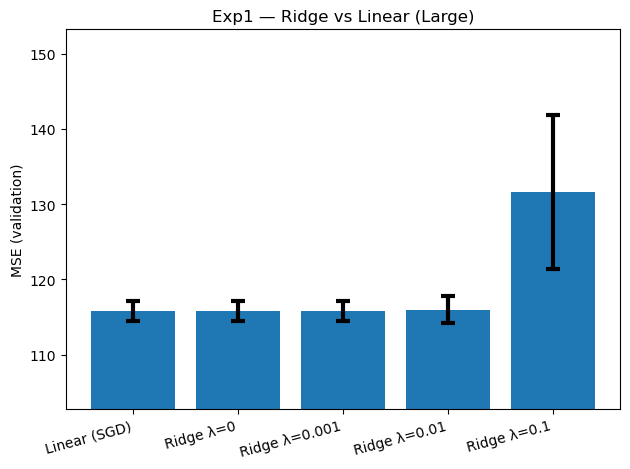

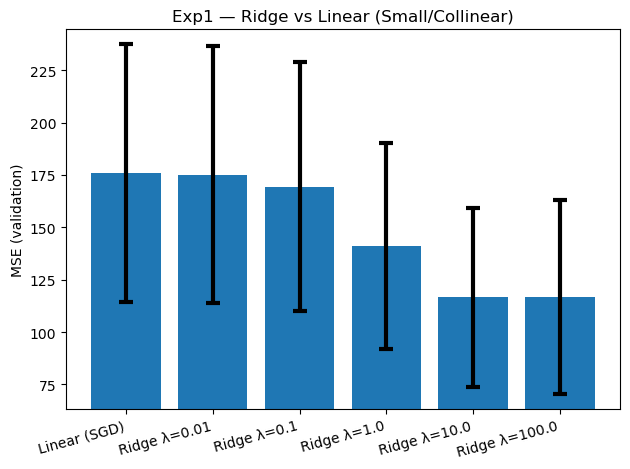

In [27]:
def make_large_well_conditioned(n=2000,
                                d=20,
                                noise=0.5,
                                seed=0):
    _RNG = np.random.default_rng(seed)
    X = _RNG.normal(size=(n, d))
    X = _add_bias(X)
    w_true = _RNG.normal(size=(d + 1, 1)) + 10
    y = _y_from_linear(X, w_true, noise, seed)
    return X, y, w_true

def make_small_collinear(n=400,
                         d=1000,
                         relevant_d=3,
                         noise=10.0,
                         rho=1.5,
                         seed=0):
    _RNG = np.random.default_rng(seed)
    cov = np.zeros((relevant_d, relevant_d))
    for ii in range(relevant_d):
        for jj in range(relevant_d):
            cov[ii, jj] = rho ** np.abs(ii - jj)
        cov[ii, ii] = 10.0
    parts = [
        _RNG.multivariate_normal(
            np.zeros(relevant_d),
            cov,
            size=(n,),
        )
    ]
    k_now = sum(p.shape[1] for p in parts)
    if d > k_now:
        parts.append(_RNG.normal(scale=0.1, size=(n, d - k_now)))
    X = np.hstack(parts)
    X = _add_bias(X)
    w_true = np.zeros((X.shape[1], 1))
    w_true[1:1 + relevant_d] = _RNG.standard_normal(size=(relevant_d, 1))
    y = _y_from_linear(X, w_true, noise, seed)
    return X, y, w_true

def exp1_ridge_vs_linear_experiment(seed=0) -> Dict[str, Any]:
    # Large
    X_L, y_L, w_L = make_large_well_conditioned(seed=seed)

    exp_L = Experiment(X_L, y_L, val_pct=0.2, seed=seed)
    cfgs_L = [
        Config("Linear (SGD)",
                lambda d: LinearRegression(in_dim=d, out_dim=1),
                lambda: SGD(eta=1e-2),
                epochs=15,
                batch_size=32,
                seed=seed),
        Config("Ridge λ=0",
                lambda d: RidgeRegression(in_dim=d, out_dim=1, lambda_=0.0),
                lambda: SGD(eta=1e-2),
                epochs=15,
                batch_size=32,
                seed=seed),
        Config("Ridge λ=0.001",
                lambda d: RidgeRegression(in_dim=d, out_dim=1, lambda_=1e-3),
                lambda: SGD(eta=1e-2),
                epochs=15,
                batch_size=32,
                seed=seed),
        Config("Ridge λ=0.01",
                lambda d: RidgeRegression(in_dim=d, out_dim=1, lambda_=1e-2),
                lambda: SGD(eta=1e-2),
                epochs=15,
                batch_size=32,
                seed=seed),
        Config("Ridge λ=0.1",
                lambda d: RidgeRegression(in_dim=d, out_dim=1, lambda_=1e-1),
                lambda: SGD(eta=1e-2),
                epochs=15,
                batch_size=32,
                seed=seed),
    ]
    res_L = exp_L.run(cfgs_L)

    res_L["name"].append("Ground truth")
    gt_mse, _ = squared_error_metrics(exp_L.Xtr, exp_L.ytr, w_L)
    res_L["train_mse"].append(gt_mse)
    gt_mse, gt_sse = squared_error_metrics(exp_L.Xval, exp_L.yval, w_L)
    res_L["val_mse"].append(gt_mse)
    res_L["val_sse"].append(gt_sse)
    res_L["epochs"].append(None)
    res_L["batch_size"].append(None)
    res_L["seed"].append(seed)
    res_L["feature_map"].append(None)
    res_L["val_size"].append(len(exp_L.yval))

    # Small/collinear
    X_S, y_S, w_S = make_small_collinear(seed=seed)
    exp_S = Experiment(X_S, y_S, val_pct=0.2, seed=seed)
    cfgs_S = [
        Config("Linear (SGD)",
                lambda d: LinearRegression(in_dim=d, out_dim=1),
                lambda: SGD(eta=1e-2),
                epochs=200,
                batch_size=32,
                seed=seed),
        Config("Ridge λ=100.0",
                lambda d: RidgeRegression(in_dim=d, out_dim=1, lambda_=100.0),
                lambda: SGD(eta=1e-2),
                epochs=200,
                batch_size=32,
                seed=seed),
        Config("Ridge λ=0.01",
                lambda d: RidgeRegression(in_dim=d, out_dim=1, lambda_=1e-2),
                lambda: SGD(eta=1e-2),
                epochs=200,
                batch_size=32,
                seed=seed),
        Config("Ridge λ=0.1",
                lambda d: RidgeRegression(in_dim=d, out_dim=1, lambda_=1e-1),
                lambda: SGD(eta=1e-2),
                epochs=200,
                batch_size=32,
                seed=seed),
        Config("Ridge λ=1.0",
                lambda d: RidgeRegression(in_dim=d, out_dim=1, lambda_=1.0),
                lambda: SGD(eta=1e-2),
                epochs=200,
                batch_size=32,
                seed=seed),
        Config("Ridge λ=10.0",
                lambda d: RidgeRegression(in_dim=d, out_dim=1, lambda_=10.0),
                lambda: SGD(eta=1e-2),
                epochs=200,
                batch_size=32,
                seed=seed),
    ]
    res_S = exp_S.run(cfgs_S)

    res_S["name"].append("Ground truth")
    gt_mse, _ = squared_error_metrics(exp_S.Xtr, exp_S.ytr, w_S)
    res_S["train_mse"].append(gt_mse)
    gt_mse, gt_sse = squared_error_metrics(exp_S.Xval, exp_S.yval, w_S)
    res_S["val_mse"].append(gt_mse)
    res_S["val_sse"].append(gt_sse)
    res_S["epochs"].append(None)
    res_S["batch_size"].append(None)
    res_S["seed"].append(seed)
    res_S["feature_map"].append(None)
    res_S["val_size"].append(len(exp_S.yval))

    return {"Large": res_L, "Small/Collinear": res_S}


def plot_exp1(save_prefix: str | None = None):
    res = exp1_ridge_vs_linear_experiment()
    for subset_name, subset_res in res.items():
        _plot_val_results(subset_res, title=f"Exp1 — Ridge vs Linear ({subset_name})")
        if save_prefix is not None:
            plt.savefig(f"{save_prefix}_exp1_{subset_name.replace('/','_').lower()}.png", dpi=160)
        
        plt.savefig("figure1.png")
        plt.show()
    return res

r1 = plot_exp1()

## Experiment 2
**Disclaimer:** We have provided the experimental results in the starter code---your implementation above might generate slightly different results due to, e.g., numerical instability.

/opt/conda/lib/python3.13/site-packages/numpy/_core/_methods.py:193: RuntimeWarning: overflow encountered in multiply
  x = um.multiply(x, x, out=x)
/opt/conda/lib/python3.13/site-packages/numpy/_core/_methods.py:204: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(x, axis, dtype, out, keepdims=keepdims, where=where)
/tmp/ipykernel_819/2015172406.py:44: RuntimeWarning: overflow encountered in divide
  self.V /= (1 - self.beta2)
/tmp/ipykernel_819/2015172406.py:43: RuntimeWarning: overflow encountered in divide
  self.M /= (1 - self.beta1)
/tmp/ipykernel_819/2015172406.py:46: RuntimeWarning: invalid value encountered in divide
  model.W -= (self.eta * self.M) / (np.sqrt(self.V) + self.eps)


ValueError: Axis limits cannot be NaN or Inf

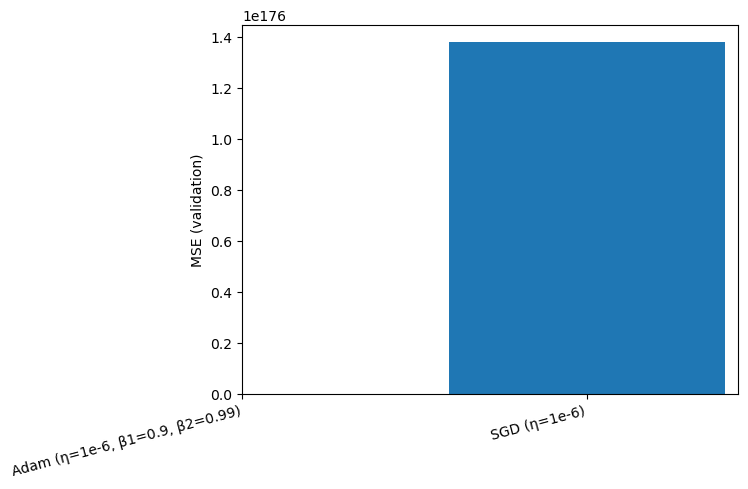

In [24]:
def make_adam_favored(n=300, d=40, noise=0.35, df=2.0, spike_frac=0.02, seed=0):
    """
    Heavy-tailed, ill-scaled, sparse-signal linear model that favors Adam.
    - Scales: 10^-3, ..., 10^3 across coordinates (anisotropy)
    - Features: Student-t(df) for heavy tails
    - Spikes: a small fraction of rows get 100x amplifications on random coords
    - Signal: very sparse true weights on 3 dims only
    """
    _RNG = np.random.default_rng(seed)
    # coordinate scales
    scales = 10 ** _RNG.uniform(-3, 3, size=d)
    # heavy-tailed features (Student-t)
    X = _RNG.standard_t(df=df, size=(n, d)) * scales

    # rare spikes (simulate outlier gradients)
    if spike_frac > 0:
        m = int(np.ceil(spike_frac * n))
        if m > 0:
            rows = _RNG.choice(n, size=m, replace=False)
            cols = _RNG.choice(d, size=m, replace=True)
            X[rows, cols] *= 10.0

    # sparse ground-truth on 3 coordinates
    w_true = np.zeros((d + 1, 1))
    idx = _RNG.choice(d, size=3, replace=False) + 1
    w_true[idx, 0] = _RNG.normal(0, 4, size=3)

    X = _add_bias(X)
    # targets with Gaussian label noise
    y = _y_from_linear(X, w_true, noise, seed)
    return X, y

def exp2_adam_vs_sgd_experiment(seed=999,) -> Dict[str, Any]:
    # Same generator: ill-scaled, sparse signal
    X, y = make_adam_favored(n=400, d=20, noise=0.2, seed=seed)

    def model_fn(d):
        return RidgeRegression(in_dim=d, out_dim=1, lambda_=0.1)

    # Keep scale heterogeneity (this is where Adam should shine)
    exp = Experiment(X, y, val_pct=0.2, seed=seed, standardize=False)

    cfgs = [
        # SGD must be extremely conservative without standardization + per-sample updates
        Config("SGD (η=1e-6)",
              model_fn,
              lambda: SGD(eta=1e-6),
              epochs=100,
              batch_size=64,
              seed=seed),

        # Adam: smaller LR + faster beta2 to handle per-sample noise and spikes
        Config("Adam (η=1e-6, β1=0.9, β2=0.99)",
              model_fn,
              lambda: Adam(eta=1e-6, beta1=0.9, beta2=0.99),
              epochs=100,
              batch_size=64,
              seed=seed),
    ]
    res = exp.run(cfgs)

    return res

def plot_exp2(save_prefix: str | None = None):
    res = exp2_adam_vs_sgd_experiment()
    _plot_val_results(res, title="Exp2 — Adam vs SGD (validation)")
    if save_prefix is not None:
        plt.savefig(f"{save_prefix}_exp2_adam_vs_sgd.png", dpi=160)
    plt.show()
    return res


r2 = plot_exp2()

## Experiment 3
**Disclaimer:** We have provided the experimental results in the starter code---your implementation above might generate slightly different results due to, e.g., numerical instability.

In [ ]:
def make_momentum_friendly(n=600, anisotropy=0.05, corr=0.95, noise=0.0, seed=999):
    _RNG = np.random.default_rng(seed)
    D = np.array([[anisotropy, 0.0],[0.0, 1.0/anisotropy]])
    theta = np.arccos(np.sqrt((1+corr)/2.0))
    R = np.array([[np.cos(theta), -np.sin(theta)],[np.sin(theta), np.cos(theta)]])
    Sigma = R @ D @ R.T
    X = _RNG.multivariate_normal(mean=[0, 0], cov=Sigma, size=n)
    w_true = np.array([[3.0],[15.0],[1.5]])
    X = _add_bias(X)
    y = _y_from_linear(X, w_true, noise, seed)
    return X, y


def exp3_adam_momentum_experiment(seed=999,) -> Dict[str, Any]:
    X, y = make_momentum_friendly(seed=seed)

    exp = Experiment(X, y, val_pct=0.2, seed=seed)
    cfgs = [
        Config("Adam β1=0.0",
                lambda d: LinearRegression(in_dim=d, out_dim=1),
                lambda: Adam(eta=1e-1, beta1=0.0, beta2=0.999),
                epochs=100,
                batch_size=32,
                seed=seed),
        Config("Adam β1=0.9",
                lambda d: LinearRegression(in_dim=d, out_dim=1),
                lambda: Adam(eta=1e-1, beta1=0.9, beta2=0.999),
                epochs=100,
                batch_size=32,
                seed=seed),
    ]
    res = exp.run(cfgs)

    return res


def plot_exp3(save_prefix: str | None = None):
    res = exp3_adam_momentum_experiment()
    df = _plot_val_results(res, title="Exp3 — Adam Momentum vs No Momentum (validation)")
    if save_prefix is not None:
        plt.savefig(f"{save_prefix}_exp3_adam_momentum.png", dpi=160)
    plt.show()
    return res

def plot_landscape():
    X, y = make_momentum_friendly(seed=999)

    w_1, w_2 = np.meshgrid(np.linspace(-20, 20, 100),
                           np.linspace(-20, 20, 100))

    W_grid = np.c_[w_1.ravel(), w_2.ravel()]
    W_grid = np.hstack((np.full((len(W_grid), 1), fill_value=1.5), W_grid))

    preds = X @ W_grid.T
    mse = 0.5 * np.mean((preds - y) ** 2, axis=0)

    plt.contourf(w_1, w_2, mse.reshape(w_1.shape), levels=20, cmap='viridis')
    plt.colorbar(label='MSE')
    plt.xlabel("$w_1$")
    plt.ylabel("$w_2$")
    plt.title("Loss landscape")
    plt.show()

plot_landscape()
r3 = plot_exp3()

## Experiment 4
**Disclaimer:** We have provided the experimental results in the starter code---your implementation above might generate slightly different results due to, e.g., numerical instability.

In [ ]:
def make_nonlinear(n=500, noise=0.0, seed=999):
    _RNG = np.random.default_rng(seed)
    X = _RNG.uniform(-2, 2, size=(n, 2))
    f = np.sin(np.pi / 2 * X[:, :1]) + 0.4 * (X[:, 1:2]**2)
    y = f + noise*_RNG.normal(size=(n, 1))
    return X, y

def exp4_prototypes_linear_experiment(seed=999,) -> Dict[str, Any]:
    X, y = make_nonlinear(seed=seed)
    def linear_fmap_fit(Xtr):
        pf = PolynomialFeatures(degree=1, include_cross=True).fit(Xtr); return pf
    def poly_fmap_fit(Xtr):
        pf = PolynomialFeatures(degree=2, include_cross=True).fit(Xtr); return pf
    def rbf_fmap_fit(Xtr):
        rbf = RadialBasisFunctionFeatures(p=100, sigma=1.0, seed=seed).fit(Xtr); return rbf

    exp = Experiment(X, y, val_pct=0.2, seed=seed)

    cfgs = [
        Config("Linear (raw)",
                lambda d: LinearRegression(in_dim=d, out_dim=1),
                lambda: SGD(eta=1e-3),
                epochs=100,
                batch_size=32,
                seed=seed,
                feature_map_fn=linear_fmap_fit),
        Config("Poly Φ (deg=2)",
                lambda d: LinearRegression(in_dim=d, out_dim=1),
                lambda: SGD(eta=1e-3),
                epochs=100,
                batch_size=32,
                seed=seed,
                feature_map_fn=poly_fmap_fit),
        Config("RBF Φ (p=100, sigma=1.0)",
                lambda d: LinearRegression(in_dim=d, out_dim=1),
                lambda: SGD(eta=1e-3),
                epochs=100,
                batch_size=32,
                seed=seed,
                feature_map_fn=rbf_fmap_fit),
    ]
    res = exp.run(cfgs)

    return res

def plot_exp4(save_prefix: str | None = None):
    res = exp4_prototypes_linear_experiment()
    _plot_val_results(res, title="Exp4 — Prototype/Feature Maps vs Linear (validation)")
    if save_prefix is not None:
        plt.savefig(f"{save_prefix}_exp4_prototypes.png", dpi=160)
    plt.show()
    return res


r4 = plot_exp4()